# DEMO TRỰC TIẾP & KIỂM THỬ HỆ THỐNG PHÂN LOẠI VĂN BẢN ESG TIẾNG VIỆT

**Mục đích:** Notebook chuyên dụng phục vụ **buổi Demo & Kiểm thử trực tiếp trước Giảng viên / Hội đồng**, sử dụng trực tiếp các checkpoint **Vòng 3 (`Run 3`)** đã huấn luyện xong (không huấn luyện lại, chỉ suy luận tức thì).

### Các chức năng demo có sẵn:
1. **Phần 1 — Nạp động cơ suy luận linh hoạt (`3 chế độ`):**
   - `"ensemble_7"` *(mặc định — cấu hình tốt nhất `Equal Soft 7M`: **90.77% Acc / 90.09% Macro-F1 / ECE = 0.0226**, ~4.5 GB VRAM RTX 5070)*.
   - `"top3_fast"` *(Top-3 mô hình mạnh nhất: `DistilBERT-m + mBERT-cased + PhoBERT-base`, ~2.0 GB VRAM)*.
   - `"single_fast"` *(1 mô hình `DistilBERT-m` siêu tốc `0.324 ms/câu`, chỉ ~0.6 GB VRAM, nạp trong ~2 giây)*.
2. **Phần 2 — Giao diện Demo tương tác (`ipywidgets`):** Nhập văn bản bất kỳ (hoặc chọn nhanh 6 câu mẫu tiêu biểu / rút ngẫu nhiên 1 câu từ tập kiểm thử khóa kín) → xem ngay **Nhãn dự đoán**, **Độ tin cậy**, **Đề xuất Human-in-the-Loop**, **Biểu đồ xác suất 4 lớp** và **Bảng phiếu bầu minh bạch của từng mô hình**.
3. **Phần 3 — Kiểm thử hàng loạt (Batch Test):** Chạy trực tiếp trên danh sách nhiều câu do giảng viên cung cấp hoặc đọc từ file `.csv` / `.txt`, xuất biểu đồ phân bố ESG và lưu kết quả ra CSV.
4. **Phần 4 — Kiểm thử ngẫu nhiên trên Hold-out Test Set (`3.000` câu khóa kín):** Đối chiếu trực tiếp **Nhãn thực tế vs Dự đoán của hệ thống** ngay tại buổi demo.
5. **Phần 5 — Giải phóng VRAM GPU gọn gàng** sau khi kết thúc buổi demo.

In [7]:
# ============================================================================
# PHẦN 1: CHỌN CHẾ ĐỘ DEMO & NẠP CÁC MÔ HÌNH RUN 3 ĐÃ HUẤN LUYỆN
# ============================================================================
import gc
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import ipywidgets as widgets
from IPython.display import display, clear_output, HTML

# Tự động định vị thư mục gốc dự án
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.config import (
    PipelineConfig,
    MODEL_REGISTRY,
    CHECKPOINTS_DIR,
    PROCESSED_DATA_DIR,
    OUTPUT_DIR,
    LABEL_NAMES,
    ID2LABEL,
    LABEL_NAMES_VI,
)
from src.model_wrapper import ESGModelWrapper
from src.preprocessing import VietnameseESGPreprocessor
from src.viz_utils import ESG_PALETTE, setup_plot_style

setup_plot_style()
cfg = PipelineConfig()

# >>> CÔNG TẮC CHỌN CHẾ ĐỘ DEMO (chỉ cần đổi 1 dòng này nếu muốn chạy nhanh/nhẹ hơn) <<<
# - "ensemble_7" : Đủ cả 7 mô hình Run 3 (Equal Soft 7M — 90.77% Acc, ECE = 0.0226)
# - "top3_fast"  : 3 mô hình dẫn đầu Run 3 (DistilBERT-m + mBERT-cased + PhoBERT-base)
# - "single_fast": 1 mô hình DistilBERT-m (89.70% Acc, độ trễ 0.324 ms/câu)
DEMO_MODE = "ensemble_7"

MODE_MODELS = {
    "ensemble_7": [
        "distilbert-base-multilingual-cased",
        "bert-base-multilingual-cased",
        "phobert-base",
        "visobert",
        "electra-base-vn",
        "roberta-base",
        "videberta-base",
    ],
    "top3_fast": [
        "distilbert-base-multilingual-cased",
        "bert-base-multilingual-cased",
        "phobert-base",
    ],
    "single_fast": [
        "distilbert-base-multilingual-cased",
    ],
}

selected_models = MODE_MODELS[DEMO_MODE]
t0 = time.perf_counter()
print(f"[DEMO] Chế độ đang nạp: {DEMO_MODE} ({len(selected_models)} mô hình Run 3)")
print(f"[DEMO] Thiết bị suy luận: {'CUDA — ' + torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU'}")

# Giải phóng phiên cũ nếu chạy lại cell này
if "demo_engines" in globals() and demo_engines:
    for _, w, _ in demo_engines:
        w.release_memory()
    demo_engines.clear()
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

demo_engines = []
for short_name in selected_models:
    spec = MODEL_REGISTRY[short_name]
    ckpt_dir = CHECKPOINTS_DIR / "run3" / short_name
    if not ckpt_dir.exists():
        raise FileNotFoundError(f"Không tìm thấy checkpoint Run 3 tại: {ckpt_dir}")
    wrapper = ESGModelWrapper(ckpt_dir).load()
    prep = VietnameseESGPreprocessor(use_word_segmenter=spec.use_word_segmenter)
    demo_engines.append((spec, wrapper, prep))

# Chạy 1 câu khởi động (warmup) để lần dự đoán đầu tiên trước giảng viên phản hồi tức thì
_warm_txt = "Doanh nghiệp cam kết giảm phát thải khí nhà kính và chuyển đổi sang năng lượng tái tạo."
for spec, wrapper, prep in demo_engines:
    _ = wrapper.predict_proba([prep.segment_text(_warm_txt)], batch_size=1, max_length=cfg.max_length, use_bf16=not spec.force_fp32, show_progress=False)

load_sec = time.perf_counter() - t0
vram_gb = (torch.cuda.memory_allocated(0) / (1024 ** 3)) if torch.cuda.is_available() else 0.0
print(f"[SẴN SÀNG] Đã nạp xong {len(demo_engines)} mô hình trong {load_sec:.1f}s | VRAM đang dùng: {vram_gb:.2f} GB")

# Nạp sẵn tập Hold-out Test (3.000 câu khóa kín) phục vụ nút rút mẫu ngẫu nhiên
test_clean_df = pd.read_csv(PROCESSED_DATA_DIR / "test_clean.csv")
print(f"[SẴN SÀNG] Đã nạp tập Hold-out Test khóa kín: {len(test_clean_df):,} câu.")

[DEMO] Chế độ đang nạp: ensemble_7 (7 mô hình Run 3)
[DEMO] Thiết bị suy luận: CUDA — NVIDIA GeForce RTX 5070
[ESGModelWrapper] Đang tải mô hình & tokenizer từ: D:\Document 2025 Backup\XuLyNgonNguTuNhien\Vi-ESG-Bert-LuuTuanTrinh\workspace_outputs\checkpoints\run3\distilbert-base-multilingual-cased
[ESGModelWrapper] Đang tải mô hình & tokenizer từ: D:\Document 2025 Backup\XuLyNgonNguTuNhien\Vi-ESG-Bert-LuuTuanTrinh\workspace_outputs\checkpoints\run3\bert-base-multilingual-cased
[ESGModelWrapper] Đang tải mô hình & tokenizer từ: D:\Document 2025 Backup\XuLyNgonNguTuNhien\Vi-ESG-Bert-LuuTuanTrinh\workspace_outputs\checkpoints\run3\phobert-base
[ESGModelWrapper] Đang tải mô hình & tokenizer từ: D:\Document 2025 Backup\XuLyNgonNguTuNhien\Vi-ESG-Bert-LuuTuanTrinh\workspace_outputs\checkpoints\run3\visobert
[ESGModelWrapper] Đang tải mô hình & tokenizer từ: D:\Document 2025 Backup\XuLyNgonNguTuNhien\Vi-ESG-Bert-LuuTuanTrinh\workspace_outputs\checkpoints\run3\electra-base-vn
[ESGModelWrapper] 

In [8]:
# Hàm suy luận lõi dùng chung cho Giao diện Tương tác, Batch Test và Kiểm thử Hold-out Test
LABEL_COLORS_HEX = {
    0: "#607D8B",  # Irrelevant - Xám
    1: "#2E7D32",  # Environment - Xanh lá
    2: "#1565C0",  # Social - Xanh dương
    3: "#E65100",  # Governance - Cam đậm
}

def predict_single_esg(raw_text: str):
    """Phân loại 1 câu tiếng Việt bằng Equal Soft Ensemble, trả về kết quả chi tiết từng mô hình."""
    engines = globals().get("demo_engines", [])
    if not engines:
        raise RuntimeError("Chưa nạp mô hình (hoặc đã giải phóng VRAM). Vui lòng chạy lại Cell Phần 1.")

    t_start = time.perf_counter()
    n_models = len(engines)
    ens_probs = np.zeros(4, dtype=np.float64)
    vote_rows = []
    pred_ids = []

    for spec, wrapper, prep in engines:
        proc_txt = prep.segment_text(raw_text)
        probs = wrapper.predict_proba(
            [proc_txt],
            batch_size=1,
            max_length=cfg.max_length,
            use_bf16=not spec.force_fp32,
            show_progress=False,
        )[0]
        ens_probs += probs / n_models
        pid = int(np.argmax(probs))
        pred_ids.append(pid)
        vote_rows.append({
            "Mô hình": spec.display_name,
            "Tách từ pyvi": "Có" if spec.use_word_segmenter else "Không",
            "Nhãn bầu": ID2LABEL[pid],
            "Độ tin cậy (%)": round(float(probs[pid]) * 100.0, 2),
            "P(Irrel)": round(float(probs[0]) * 100.0, 1),
            "P(Env)": round(float(probs[1]) * 100.0, 1),
            "P(Soc)": round(float(probs[2]) * 100.0, 1),
            "P(Gov)": round(float(probs[3]) * 100.0, 1),
        })

    elapsed_ms = (time.perf_counter() - t_start) * 1000.0
    sorted_p = np.sort(ens_probs)
    final_id = int(np.argmax(ens_probs))
    final_conf = float(ens_probs[final_id]) * 100.0
    margin_pct = float(sorted_p[-1] - sorted_p[-2]) * 100.0
    consensus_votes = sum(1 for p in pred_ids if p == final_id)

    return {
        "final_id": final_id,
        "final_label": ID2LABEL[final_id],
        "final_label_vi": LABEL_NAMES_VI[final_id],
        "confidence_pct": final_conf,
        "margin_pct": margin_pct,
        "consensus_str": f"{consensus_votes}/{n_models}",
        "elapsed_ms": elapsed_ms,
        "ens_probs": ens_probs,
        "vote_df": pd.DataFrame(vote_rows),
    }

def predict_batch_esg(texts, batch_size: int = 32):
    """Phân loại hàng loạt nhiều câu văn bản tiếng Việt bằng Equal Soft Ensemble."""
    engines = globals().get("demo_engines", [])
    if not engines:
        raise RuntimeError("Chưa nạp mô hình. Vui lòng chạy lại Cell Phần 1.")
    texts = [str(t).strip() for t in texts]
    t_start = time.perf_counter()
    n_models = len(engines)
    ens_probs = np.zeros((len(texts), 4), dtype=np.float64)
    all_votes = []

    for spec, wrapper, prep in engines:
        proc_texts = [prep.segment_text(t) for t in texts]
        probs = wrapper.predict_proba(
            proc_texts,
            batch_size=batch_size,
            max_length=cfg.max_length,
            use_bf16=not spec.force_fp32,
            show_progress=False,
        )
        ens_probs += probs / n_models
        all_votes.append(np.argmax(probs, axis=1))

    elapsed_sec = time.perf_counter() - t_start
    votes_mat = np.stack(all_votes, axis=0)  # (n_models, n_samples)
    pred_ids = np.argmax(ens_probs, axis=1)
    sorted_p = np.sort(ens_probs, axis=1)
    confs = ens_probs[np.arange(len(texts)), pred_ids] * 100.0
    margins = (sorted_p[:, -1] - sorted_p[:, -2]) * 100.0
    consensus = [f"{int(np.sum(votes_mat[:, i] == pred_ids[i]))}/{n_models}" for i in range(len(texts))]

    out_df = pd.DataFrame({
        "Văn bản": texts,
        "Nhãn dự đoán": [ID2LABEL[int(p)] for p in pred_ids],
        "Nhãn tiếng Việt": [LABEL_NAMES_VI[int(p)] for p in pred_ids],
        "Độ tin cậy (%)": np.round(confs, 2),
        "Margin (%)": np.round(margins, 2),
        "Đồng thuận": consensus,
        "Gợi ý kiểm duyệt": ["Tự động duyệt (>=90%)" if c >= 90.0 else "Chuyên gia xem xét" for c in confs],
    })
    return out_df, elapsed_sec

print("[OK] Đã sẵn sàng hàm suy luận đơn lẻ và suy luận hàng loạt!")

[OK] Đã sẵn sàng hàm suy luận đơn lẻ và suy luận hàng loạt!


---
## Phần 2 — Giao diện Demo Trực tiếp trước Giảng viên (`ipywidgets`)

- Chọn nhanh **6 câu mẫu tiêu biểu** (4 lớp ESG cơ bản + 1 câu tình huống biên *Social/Governance* + 1 câu báo cáo tài chính thuần túy *Irrelevant*), **hoặc** bấm nút **"Rút ngẫu nhiên 1 câu từ Hold-out Test"** để thử nghiệm khách quan trên dữ liệu khóa kín, **hoặc** nhập trực tiếp bất kỳ câu nào giảng viên yêu cầu!

In [9]:
# ============================================================================
# PHẦN 2: GIAO DIỆN DEMO TƯƠNG TÁC TRỰC TIẾP
# ============================================================================
SAMPLE_TEXTS = {
    "1. Môi trường (Environment)": "Tập đoàn cam kết cắt giảm 45% lượng phát thải khí nhà kính phạm vi 1 và 2 vào năm 2030 thông qua chuyển đổi sang điện mặt trời áp mái và tái chế 90% nước thải công nghiệp.",
    "2. Xã hội (Social)": "Trong năm tài chính vừa qua, doanh nghiệp đã chi hơn 120 tỷ đồng cho các chương trình đào tạo nâng cao tay nghề nhân viên, bảo hiểm sức khỏe toàn diện và học bổng cho học sinh vùng cao.",
    "3. Quản trị (Governance)": "Hội đồng quản trị đã ban hành quy chế quản trị rủi ro cập nhật, thiết lập Ủy ban Kiểm toán độc lập gồm 100% thành viên không điều hành nhằm đảm bảo tính minh bạch với cổ đông.",
    "4. Không liên quan (Irrelevant)": "Doanh thu quý 3 của công ty tăng trưởng 12% nhờ mở rộng thêm 15 điểm bán lẻ mới tại khu vực miền Trung và tối ưu hóa chi phí vận chuyển kho bãi.",
    "5. Ca biên khó (Social ↔ Governance)": "Hội đồng quản trị đã họp thông qua chính sách tăng tỷ lệ nữ lãnh đạo lên 40% và bổ sung chế độ chăm sóc sức khỏe tinh thần cho toàn bộ người lao động.",
    "6. Tài chính thuần túy (dễ nhầm Gov)": "Theo chuẩn mực kế toán hiện hành, báo cáo tài chính hợp nhất của tập đoàn ghi nhận khoản vay ngắn hạn liên công ty với lãi suất thả nổi theo thị trường.",
}

state_true_label = {"value": None}  # Lưu nhãn thực tế nếu câu được rút từ Hold-out Test

sample_dropdown = widgets.Dropdown(
    options=list(SAMPLE_TEXTS.keys()),
    description="Câu mẫu:",
    layout=widgets.Layout(width="360px"),
)
btn_predict = widgets.Button(description="Phân loại ESG", button_style="success", icon="play")
btn_random_test = widgets.Button(description="Rút ngẫu nhiên từ Test Set", button_style="info", icon="random", layout=widgets.Layout(width="220px"))
text_area = widgets.Textarea(
    value=SAMPLE_TEXTS["1. Môi trường (Environment)"],
    placeholder="Nhập câu hoặc đoạn trích báo cáo doanh nghiệp tiếng Việt tại đây...",
    description="Văn bản:",
    layout=widgets.Layout(width="98%", height="90px"),
)
# Dùng widgets.HTML thay cho Output + plt.show() để KHÔNG BAO GIỜ bị lỗi trắng hình / che khuất trên JupyterLab 4
result_view = widgets.HTML(
    value="<i>Đang khởi tạo kết quả...</i>",
    layout=widgets.Layout(width="98%", overflow="visible"),
)

def _build_dashboard_html(res, true_label_str=None):
    color_hex = LABEL_COLORS_HEX[res["final_id"]]
    hitl_badge = (
        "<span style='background:#E8F5E9;color:#1B5E20;padding:3px 8px;border-radius:4px;font-weight:bold;'>Tự động phê duyệt (Confidence &ge; 90% — Độ chính xác thực nghiệm 97.41%)</span>"
        if res["confidence_pct"] >= 90.0
        else "<span style='background:#FFF3E0;color:#E65100;padding:3px 8px;border-radius:4px;font-weight:bold;'>Đề xuất chuyên gia ESG rà soát (Confidence &lt; 90%)</span>"
    )
    truth_html = ""
    if true_label_str is not None:
        is_ok = (true_label_str == res["final_label"])
        verdict = "<b style='color:#2E7D32;'>KHỚP CHÍNH XÁC</b>" if is_ok else "<b style='color:#C62828;'>KHÁC NHÃN GỐC</b>"
        truth_html = f"<div style='margin-top:6px;font-size:13px;'><b>Nhãn thực tế trong Hold-out Test:</b> <code style='background:#ECEFF1;padding:2px 6px;border-radius:3px;'>{true_label_str}</code> &rarr; {verdict}</div>"

    # Biểu đồ thanh ngang xác suất 4 lớp bằng HTML/CSS (hiển thị tức thì, không bao giờ bị che cắt)
    probs_pct = res["ens_probs"] * 100.0
    bars_rows_html = ""
    for cid, lname in enumerate(LABEL_NAMES):
        val = float(probs_pct[cid])
        bar_col = LABEL_COLORS_HEX[cid]
        bar_w = max(val, 0.4)
        bold_style = "font-weight:bold;color:#111;" if cid == res["final_id"] else "color:#444;"
        bars_rows_html += f"""
        <tr>
          <td style="width:120px;padding:5px 8px 5px 0;font-size:13px;{bold_style}">{lname}</td>
          <td style="padding:5px 8px;">
            <div style="background:#ECEFF1;border-radius:4px;height:20px;width:100%;overflow:hidden;">
              <div style="background:{bar_col};height:20px;width:{bar_w:.2f}%;border-radius:4px;"></div>
            </div>
          </td>
          <td style="width:72px;text-align:right;padding:5px 0 5px 8px;font-size:13px;{bold_style}">{val:.2f}%</td>
        </tr>
        """

    # Bảng phiếu bầu chi tiết của từng mô hình thành viên
    vote_rows_html = ""
    for idx, r in res["vote_df"].iterrows():
        bg = "#FFFFFF" if idx % 2 == 0 else "#F8F9FA"
        match_style = "color:#1B5E20;font-weight:bold;" if r["Nhãn bầu"] == res["final_label"] else "color:#C62828;font-weight:bold;"
        vote_rows_html += f"""
        <tr style="background:{bg};border-bottom:1px solid #E0E0E0;">
          <td style="padding:6px 10px;font-weight:600;">{r['Mô hình']}</td>
          <td style="padding:6px 8px;text-align:center;">{r['Tách từ pyvi']}</td>
          <td style="padding:6px 10px;{match_style}">{r['Nhãn bầu']}</td>
          <td style="padding:6px 8px;text-align:right;font-weight:bold;">{r['Độ tin cậy (%)']:.2f}%</td>
          <td style="padding:6px 8px;text-align:right;color:#555;">{r['P(Irrel)']:.1f}%</td>
          <td style="padding:6px 8px;text-align:right;color:#555;">{r['P(Env)']:.1f}%</td>
          <td style="padding:6px 8px;text-align:right;color:#555;">{r['P(Soc)']:.1f}%</td>
          <td style="padding:6px 8px;text-align:right;color:#555;">{r['P(Gov)']:.1f}%</td>
        </tr>
        """

    return f"""
    <div style="font-family:Segoe UI,Arial,sans-serif;color:#222;line-height:1.45;">
      <div style="border-left:6px solid {color_hex};background:#F8F9FA;padding:12px 16px;border-radius:6px;margin:8px 0 12px 0;border-top:1px solid #E0E0E0;border-right:1px solid #E0E0E0;border-bottom:1px solid #E0E0E0;">
        <div style="font-size:18px;font-weight:bold;color:{color_hex};">KẾT QUẢ DỰ ĐOÁN: {res['final_label_vi']}</div>
        <div style="margin-top:6px;font-size:13.5px;">
          <b>Độ tin cậy Ensemble:</b> {res['confidence_pct']:.2f}% &nbsp;|&nbsp;
          <b>Độ chênh lệch (Margin):</b> {res['margin_pct']:.2f}% &nbsp;|&nbsp;
          <b>Đồng thuận:</b> {res['consensus_str']} mô hình &nbsp;|&nbsp;
          <b>Thời gian:</b> {res['elapsed_ms']:.1f} ms
        </div>
        <div style="margin-top:6px;font-size:13px;"><b>Cơ chế Human-in-the-Loop:</b> {hitl_badge}</div>
        {truth_html}
      </div>

      <div style="background:#FFFFFF;border:1px solid #E0E0E0;border-radius:6px;padding:12px 16px;margin-bottom:12px;">
        <div style="font-weight:bold;font-size:14px;margin-bottom:6px;color:#222;">Phân phối xác suất 4 lớp ESG (Chế độ: <code>{DEMO_MODE}</code>)</div>
        <table style="width:100%;border-collapse:collapse;">{bars_rows_html}</table>
      </div>

      <div style="background:#FFFFFF;border:1px solid #E0E0E0;border-radius:6px;padding:12px 16px;">
        <div style="font-weight:bold;font-size:14px;margin-bottom:8px;color:#222;">Bảng phiếu bầu chi tiết của từng mô hình thành viên</div>
        <table style="width:100%;border-collapse:collapse;font-size:12.5px;">
          <thead>
            <tr style="background:#ECEFF1;border-bottom:2px solid #B0BEC5;">
              <th style="padding:7px 10px;text-align:left;">Mô hình</th>
              <th style="padding:7px 8px;text-align:center;">Tách từ pyvi</th>
              <th style="padding:7px 10px;text-align:left;">Nhãn bầu</th>
              <th style="padding:7px 8px;text-align:right;">Độ tin cậy</th>
              <th style="padding:7px 8px;text-align:right;">P(Irrel)</th>
              <th style="padding:7px 8px;text-align:right;">P(Env)</th>
              <th style="padding:7px 8px;text-align:right;">P(Soc)</th>
              <th style="padding:7px 8px;text-align:right;">P(Gov)</th>
            </tr>
          </thead>
          <tbody>{vote_rows_html}</tbody>
        </table>
      </div>
    </div>
    """

def _run_predict_ui():
    txt = text_area.value.strip()
    if not txt:
        result_view.value = "<div style='color:#C62828;padding:8px;'>Vui lòng nhập văn bản tiếng Việt để phân loại.</div>"
        return
    try:
        res = predict_single_esg(txt)
        result_view.value = _build_dashboard_html(res, true_label_str=state_true_label["value"])
    except Exception as exc:
        result_view.value = f"<div style='color:#C62828;padding:8px;'><b>Lỗi:</b> {exc}</div>"

def _on_sample_change(change):
    if change["name"] == "value":
        state_true_label["value"] = None
        text_area.value = SAMPLE_TEXTS[change["new"]]
        _run_predict_ui()

def _on_random_test(_):
    row = test_clean_df.sample(1).iloc[0]
    state_true_label["value"] = ID2LABEL[int(row[cfg.label_column])]
    text_area.value = str(row[cfg.text_column])
    _run_predict_ui()

def _on_predict(_):
    _run_predict_ui()

sample_dropdown.observe(_on_sample_change, names="value")
btn_predict.on_click(_on_predict)
btn_random_test.on_click(_on_random_test)

display(widgets.VBox(
    [widgets.HBox([sample_dropdown, btn_predict, btn_random_test]), text_area, result_view],
    layout=widgets.Layout(width="100%", overflow="visible"),
))
# Tự động chạy sẵn câu mẫu đầu tiên để giao diện hiển thị ngay kết quả trực quan
_run_predict_ui()

---
## Phần 3 — Kiểm thử Hàng loạt (Batch Test: Nhiều câu hoặc File `.csv` / `.txt` của Giảng viên)

Bạn có thể dán trực tiếp nhiều câu vào danh sách `CUSTOM_SENTENCES` bên dưới (hoặc truyền đường dẫn file `.csv` chứa cột văn bản) để hệ thống phân loại toàn bộ trong vài giây, vẽ biểu đồ cơ cấu ESG của tài liệu và xuất ra `workspace_outputs/demo_predictions.csv`.

[Batch Test] Chạy trên 8 câu mẫu tùy chỉnh...
[HOÀN TẤT] Xử lý 8 câu trong 0.11s (73.3 câu/giây)


,Văn bản,Nhãn dự đoán,Nhãn tiếng Việt,Độ tin cậy (%),Margin (%),Đồng thuận,Gợi ý kiểm duyệt
0,Nhà máy đã lắp đặt hệ thống thu hồi nhiệt dư g...,Environment,Môi trường (Environment),99.98,99.98,7/7,Tự động duyệt (>=90%)
1,Công ty duy trì 100% người lao động được ký hợ...,Social,Xã hội (Social),99.89,99.85,7/7,Tự động duyệt (>=90%)
2,Đại hội đồng cổ đông đã phê duyệt điều lệ sửa ...,Governance,Quản trị (Governance),99.89,99.84,7/7,Tự động duyệt (>=90%)
3,Quý 4 năm nay công ty ra mắt dòng sản phẩm đồ ...,Irrelevant,Không liên quan (Irrelevant),93.50,87.58,7/7,Tự động duyệt (>=90%)
4,100% bao bì nhựa nguyên sinh tại các dây chuyề...,Environment,Môi trường (Environment),99.95,99.93,7/7,Tự động duyệt (>=90%)
5,Ủy ban Kiểm toán tiến hành rà soát độc lập hệ ...,Governance,Quản trị (Governance),99.96,99.94,7/7,Tự động duyệt (>=90%)
6,Doanh nghiệp tài trợ xây dựng 5 điểm trường ti...,Social,Xã hội (Social),98.71,97.56,7/7,Tự động duyệt (>=90%)
7,Lợi nhuận sau thuế hợp nhất cả năm đạt 850 tỷ ...,Governance,Quản trị (Governance),79.60,59.26,6/7,Chuyên gia xem xét


[Đã lưu kết quả] D:\Document 2025 Backup\XuLyNgonNguTuNhien\Vi-ESG-Bert-LuuTuanTrinh\workspace_outputs\demo_predictions.csv


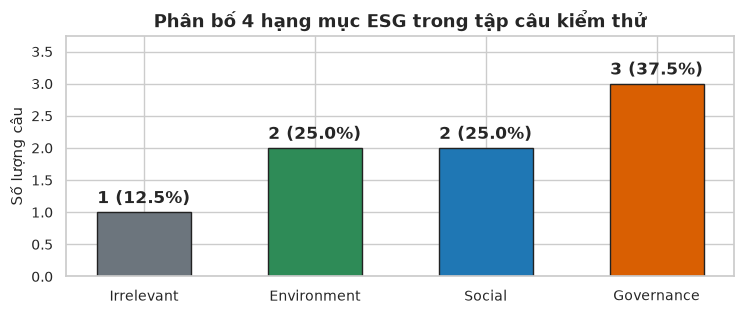

In [10]:
# ============================================================================
# PHẦN 3: KIỂM THỬ HÀNG LOẠT (BATCH TEST)
# ============================================================================
# Cách A: Nhập trực tiếp danh sách câu cần test (có thể thay đổi ngay trước mặt giảng viên)
CUSTOM_SENTENCES = [
    "Nhà máy đã lắp đặt hệ thống thu hồi nhiệt dư giúp giảm 18% lượng điện tiêu thụ và cắt giảm 2.400 tấn CO2 mỗi năm.",
    "Công ty duy trì 100% người lao động được ký hợp đồng chính thức, đóng đầy đủ bảo hiểm xã hội và khám sức khỏe định kỳ hằng năm.",
    "Đại hội đồng cổ đông đã phê duyệt điều lệ sửa đổi, quy định rõ cơ chế phòng chống xung đột lợi ích và công bố thông tin giao dịch bên liên quan.",
    "Quý 4 năm nay công ty ra mắt dòng sản phẩm đồ uống không đường mới phân phối tại hơn 2.000 siêu thị toàn quốc.",
    "100% bao bì nhựa nguyên sinh tại các dây chuyền đóng gói đã được thay thế bằng nhựa tái chế rPET thân thiện môi trường.",
    "Ủy ban Kiểm toán tiến hành rà soát độc lập hệ thống kiểm soát nội bộ và tuân thủ pháp luật phòng chống tham nhũng tại tất cả công ty con.",
    "Doanh nghiệp tài trợ xây dựng 5 điểm trường tiểu học và cung cấp nước sạch sinh hoạt cho 3.000 hộ dân khu vực miền núi.",
    "Lợi nhuận sau thuế hợp nhất cả năm đạt 850 tỷ đồng, hoàn thành 108% kế hoạch kinh doanh đề ra.",
]

# Cách B (Tùy chọn): Nếu giảng viên đưa 1 file CSV mới, điền đường dẫn vào đây (để None nếu dùng Cách A)
EXTERNAL_CSV_PATH = None   # Ví dụ: r"D:\path\to\file_test_giang_vien.csv"
EXTERNAL_TEXT_COL = "vi_text"

if EXTERNAL_CSV_PATH is not None:
    ext_df = pd.read_csv(EXTERNAL_CSV_PATH)
    batch_texts = ext_df[EXTERNAL_TEXT_COL].dropna().astype(str).tolist()
    print(f"[Batch Test] Đọc {len(batch_texts):,} câu từ file: {EXTERNAL_CSV_PATH}")
else:
    batch_texts = CUSTOM_SENTENCES
    print(f"[Batch Test] Chạy trên {len(batch_texts):,} câu mẫu tùy chỉnh...")

batch_result_df, batch_sec = predict_batch_esg(batch_texts, batch_size=32)
print(f"[HOÀN TẤT] Xử lý {len(batch_result_df):,} câu trong {batch_sec:.2f}s ({len(batch_result_df)/max(batch_sec,1e-6):.1f} câu/giây)")
display(batch_result_df)

# Xuất kết quả ra CSV
save_demo_csv = OUTPUT_DIR / "demo_predictions.csv"
batch_result_df.to_csv(save_demo_csv, index=False, encoding="utf-8-sig")
print(f"[Đã lưu kết quả] {save_demo_csv}")

# Vẽ biểu đồ cơ cấu 4 lớp ESG trong tập câu vừa kiểm thử
counts = batch_result_df["Nhãn dự đoán"].value_counts().reindex(LABEL_NAMES, fill_value=0)
fig, ax = plt.subplots(figsize=(7.6, 3.3))
bars = ax.bar(LABEL_NAMES, counts.values, color=[ESG_PALETTE[n] for n in LABEL_NAMES], edgecolor="#222222", width=0.55)
ax.set_ylabel("Số lượng câu")
ax.set_title("Phân bố 4 hạng mục ESG trong tập câu kiểm thử", fontweight="bold")
ax.set_ylim(0, max(counts.values) * 1.25 if max(counts.values) > 0 else 5)
for bar, v in zip(bars, counts.values):
    ax.text(bar.get_x() + bar.get_width()/2, v + 0.08, f"{int(v)} ({v/len(batch_result_df)*100:.1f}%)", ha="center", va="bottom", fontweight="bold")
plt.tight_layout()
plt.show()

---
## Phần 4 — Kiểm thử Ngẫu nhiên trên Tập Hold-out Test Khóa kín (`test_clean.csv`)

Chạy cell dưới đây để rút ngẫu nhiên `N = 10` câu bất kỳ từ tập kiểm thử khóa kín (chưa từng dùng để huấn luyện hay chọn checkpoint) và chấm điểm trực tiếp trước mặt giảng viên!

In [11]:
# ============================================================================
# PHẦN 4: KIỂM THỬ NGẪU NHIÊN TRÊN HOLD-OUT TEST SET (3.000 CÂU KHÓA KÍN)
# ============================================================================
N_SPOT_CHECK = 10  # Có thể đổi thành 20, 50 tùy yêu cầu giảng viên

sample_df = test_clean_df.sample(N_SPOT_CHECK).reset_index(drop=True)
pred_df, sec = predict_batch_esg(sample_df[cfg.text_column].tolist(), batch_size=32)

pred_df.insert(1, "Nhãn thực tế (Test)", [ID2LABEL[int(y)] for y in sample_df[cfg.label_column]])
pred_df["Kết quả"] = np.where(pred_df["Nhãn thực tế (Test)"] == pred_df["Nhãn dự đoán"], "ĐÚNG", "SAI")
pred_df["Văn bản"] = pred_df["Văn bản"].str.slice(0, 120) + "..."

n_correct = int((pred_df["Kết quả"] == "ĐÚNG").sum())
print(f"[KIỂM THỬ NGẪU NHIÊN] Đúng {n_correct}/{N_SPOT_CHECK} câu ({n_correct/N_SPOT_CHECK*100:.1f}%) | Thời gian: {sec:.2f}s")
display(pred_df[["Văn bản", "Nhãn thực tế (Test)", "Nhãn dự đoán", "Độ tin cậy (%)", "Đồng thuận", "Kết quả"]])

[KIỂM THỬ NGẪU NHIÊN] Đúng 8/10 câu (80.0%) | Thời gian: 0.24s


,Văn bản,Nhãn thực tế (Test),Nhãn dự đoán,Độ tin cậy (%),Đồng thuận,Kết quả
0,khí thải từ động thải được tạo ra từ sự đốt ch...,Environment,Environment,99.98,7/7,ĐÚNG
1,một vấn đề trọng tâm trong báo cáo của geberir...,Social,Social,86.06,6/7,ĐÚNG
2,công ty đối tác - jean-michel cousteau - hiệp ...,Social,Social,77.25,6/7,ĐÚNG
3,nhóm bằng sáng chế này bao gồm một bằng sáng c...,Irrelevant,Irrelevant,71.26,5/7,ĐÚNG
4,"mặc dù vậy, công ty đã không đình chỉ các hoạt...",Social,Social,99.83,7/7,ĐÚNG
5,ủy ban kiểm toán và rủi ro thực hiện đánh giá ...,Governance,Governance,99.95,7/7,ĐÚNG
6,công ty đạt được những thành quả lớn trong việ...,Environment,Environment,99.98,7/7,ĐÚNG
7,công ty chúng tôi tiếp tục lắp đặt các thiết b...,Environment,Environment,99.98,7/7,ĐÚNG
8,tiếp theo việc hợp nhất fp gmbh và công nhận k...,Irrelevant,Governance,99.89,7/7,SAI
9,công ty chúng tôi đã định ra một quy luật hướn...,Social,Governance,77.49,6/7,SAI


---
## Phần 5 — Dọn dẹp & Giải phóng Bộ nhớ GPU sau khi Demo xong

Chạy cell cuối này sau khi kết thúc buổi trình bày để trả sạch VRAM về 0 GB cho RTX 5070.

In [12]:
# Giải phóng toàn bộ mô hình Demo khỏi VRAM
if "demo_engines" in globals() and demo_engines:
    for _, w, _ in demo_engines:
        w.release_memory()
    demo_engines.clear()
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()
    vram_after = torch.cuda.memory_allocated(0) / (1024 ** 3)
    print(f"[HOÀN TẤT] Đã giải phóng bộ nhớ GPU! VRAM hiện tại: {vram_after:.3f} GB")
else:
    print("[HOÀN TẤT] Đã giải phóng bộ nhớ RAM!")

[HOÀN TẤT] Đã giải phóng bộ nhớ GPU! VRAM hiện tại: 0.018 GB
